# <center> ⚔️ **LLM Arena** ⚔️
---

In [1]:
!pip install seaborn -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json

plt.style.use('ggplot')

In [3]:
# Enter model IDs:
model1 = input("Enter 1st contestant ID:")
model2 = input("Enter 2nd contestant ID:")

Enter 1st contestant ID: base-model
Enter 2nd contestant ID: ISO-500


In [4]:
# Calculate mean skill values for each test...

def calculate_mean_skills(json_files):
    sums = {}
    count = len(json_files)

    # Read JSON skill files
    for file in json_files:
        with open(file, 'r') as f:
            data = json.load(f)
            for key, value in data.items():
                if key in sums:
                    sums[key] += value
                else:
                    sums[key] = value

    means = {key: value / count for key, value in sums.items()}
    return means

model1_files = [f'exams/results/{model1}-r{i+1}.json' for i in range(3)]
model2_files = [f'exams/results/{model2}-r{i+1}.json' for i in range(3)]

skill_dict1 = calculate_mean_skills(model1_files)
skill_dict2 = calculate_mean_skills(model2_files)

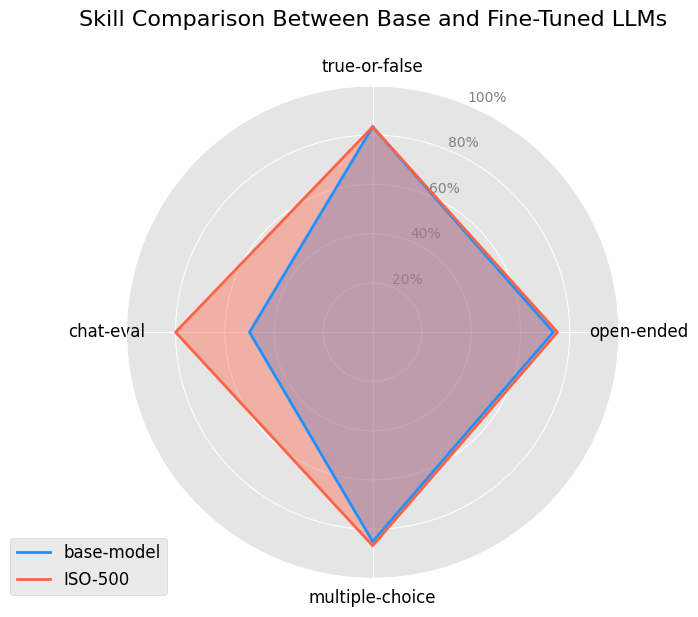

In [5]:
# Extract labels and values from the dictionaries
labels = list(skill_dict1.keys())
values1 = list(skill_dict1.values())
values2 = list(skill_dict2.values())

# Add the first value to the end to close the pentagon
values1 += values1[:1]
values2 += values2[:1]

# PENTAGON PLOT:

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

plt.xticks(angles[:-1], labels, color='black', size=12)
ax.set_rscale('linear')
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["20%", "40%", "60%", "80%", "100%"], color="grey", size=10)
plt.ylim(0, 1)

ax.plot(angles, values1, linewidth=2, linestyle='solid', label=model1, color='dodgerblue')
ax.fill(angles, values1, color='dodgerblue', alpha=0.4)
ax.plot(angles, values2, linewidth=2, linestyle='solid', label=model2, color='tomato')
ax.fill(angles, values2, color='tomato', alpha=0.4)
ax.set_title('Skill Comparison Between Base and Fine-Tuned LLMs\n', fontsize=16)

plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), fontsize=12)
plt.tight_layout()
plt.show()

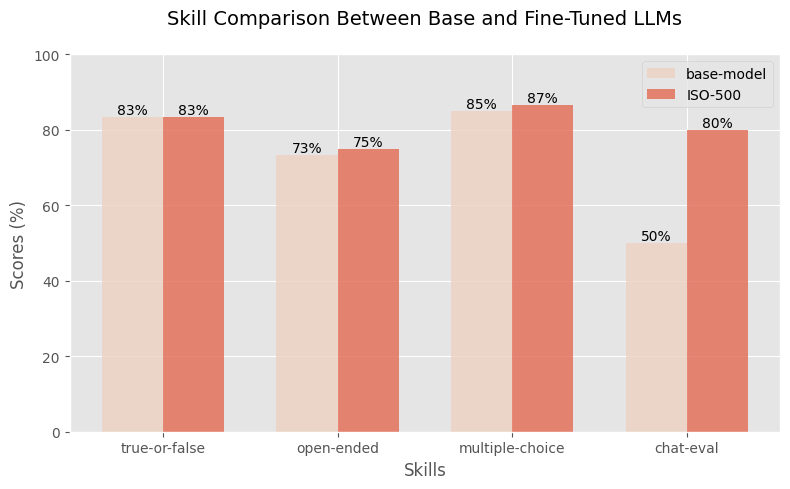

In [6]:
# Extract labels and convert values to percentages
labels = list(skill_dict1.keys())
values1 = [v * 100 for v in skill_dict1.values()]
values2 = [v * 100 for v in skill_dict2.values()]

# BAR PLOT:

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

sns.set_palette("coolwarm")
colors = sns.color_palette("coolwarm")

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, values1, width, label=model1, color=colors[3], alpha=0.8)
bars2 = ax.bar(x + width/2, values2, width, label=model2, color=colors[5], alpha=0.8)

ax.set_xlabel('Skills')
ax.set_ylabel('Scores (%)')
ax.set_title('Skill Comparison Between Base and Fine-Tuned LLMs\n', fontsize=14)
#plt.xticks(rotation=30, ha="right")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

def add_value_labels(bars):
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.0f}%', va='bottom', ha='center')

add_value_labels(bars1)
add_value_labels(bars2)

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

---